# NHS.UK Health A-Z: classificador de urgência com LLM e RAG

Trabalho da Unidade 4. Equipe: Guilherme Moll

1. TF-IDF + Regressão Logística da Unidade 3 com um tokenizador que também roda no navegador, exportado para o site
2. comparação da Regressão Logística com o Gemini sem exemplos e com o Gemini usando trechos recuperados do corpus (RAG)
3. frases novas em inglês e em português

chamadas ao Gemini com a variável de ambiente `GEMINI_API_KEY`, respostas guardadas em `cache_gemini.json` para rodar de novo sem chave

## 0. Dados

Mesma limpeza, deduplicação e amostra de 4.000 passagens da Unidade 3

In [1]:
import gzip, json, re, time, os, hashlib, unicodedata, urllib.request, urllib.error
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_colwidth", 90)
SEMENTE = 42

with gzip.open("../data/passages.jsonl.gz", "rt", encoding="utf-8") as fh:
    passages = [json.loads(linha) for linha in fh]

TAG = re.compile(r"<[^>]+>")
ENTIDADE = re.compile(r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);")
URL = re.compile(r"https?://\S+|www\.\S+")
ESPACOS = re.compile(r"[ \t\xa0]+")
LINHAS = re.compile(r"\n{2,}")
TIPOGRAFICOS = {"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": "-", "…": "...", "­": ""}


def limpar(texto):
    if not texto:
        return ""
    texto = unicodedata.normalize("NFKC", texto)
    for de, para in TIPOGRAFICOS.items():
        texto = texto.replace(de, para)
    texto = ENTIDADE.sub(" ", TAG.sub(" ", texto))
    texto = URL.sub(" ", texto)
    texto = LINHAS.sub("\n", ESPACOS.sub(" ", texto))
    return "\n".join(l.strip() for l in texto.split("\n")).strip()

tokenizador `[a-z]+` no lugar do `word_tokenize` do NLTK, o mesmo que o site usa em JavaScript

stopwords da Unidade 3, mantendo negação e modalidade

In [2]:
nltk.download("stopwords", quiet=True)
NEGACAO = frozenset({
    "no", "nor", "not", "don", "dont", "ain", "aren", "arent",
    "couldn", "couldnt", "didn", "didnt", "doesn", "doesnt",
    "hadn", "hadnt", "hasn", "hasnt", "haven", "havent", "isn", "isnt",
    "mightn", "mightnt", "mustn", "mustnt", "needn", "neednt",
    "shan", "shant", "shouldn", "shouldnt", "wasn", "wasnt",
    "weren", "werent", "won", "wont", "wouldn", "wouldnt",
    "against", "few", "more", "most", "very", "only", "same",
})
STOPWORDS = frozenset(stopwords.words("english")) - NEGACAO
PALAVRA = re.compile(r"[a-z]+")


def preparar(texto):
    return [t for t in PALAVRA.findall(unicodedata.normalize("NFKC", texto).lower()) if t not in STOPWORDS]


corpus = pd.DataFrame(passages)
corpus["clean_text"] = corpus["raw_text"].map(limpar)
corpus["chave"] = corpus["clean_text"].str.casefold().str.split().str.join(" ")
rotulos_por_texto = corpus.groupby("chave")["urgency"].nunique()
unicos = corpus[~corpus["chave"].isin(rotulos_por_texto[rotulos_por_texto > 1].index)].drop_duplicates("chave").copy()
unicos["tokens"] = unicos["clean_text"].map(preparar)
unicos = unicos[unicos["tokens"].str.len() >= 3]

rotuladas = unicos[unicos["urgency"] != "informational"]
informativas = unicos[unicos["urgency"] == "informational"].sample(4000 - len(rotuladas), random_state=SEMENTE)
base = pd.concat([rotuladas, informativas]).sample(frac=1, random_state=SEMENTE).reset_index(drop=True)
print(f"passagens sem duplicata: {len(unicos):,}   base: {len(base):,}")
base["urgency"].value_counts().to_frame("passagens")

passagens sem duplicata: 18,011   base: 4,000


,passagens
urgency,
informational,1614
self_care,940
urgent,568
non_urgent,531
emergency,347


## 1. Classificador da Unidade 3 com o tokenizador novo

TF-IDF ajustado só no treino, Regressão Logística, 80/20 estratificado

In [3]:
CLASSES = ["emergency", "urgent", "non_urgent", "self_care"]
rot = base[base["urgency"] != "informational"]
idx_treino, idx_teste = train_test_split(rot.index, test_size=0.2, stratify=rot["urgency"], random_state=SEMENTE)
y_treino, y_teste = base.loc[idx_treino, "urgency"], base.loc[idx_teste, "urgency"]

tfidf = TfidfVectorizer(analyzer=lambda t: t, min_df=2).fit(base.loc[idx_treino, "tokens"])
modelo = LogisticRegression(max_iter=3000).fit(tfidf.transform(base.loc[idx_treino, "tokens"]), y_treino)


def classificar(textos):
    return modelo.predict(tfidf.transform([preparar(t) for t in textos]))


prev_rl = modelo.predict(tfidf.transform(base.loc[idx_teste, "tokens"]))
print(f"treino: {len(idx_treino):,}   teste: {len(idx_teste):,}   vocabulário: {len(tfidf.vocabulary_):,}")
print(f"F1 macro {f1_score(y_teste, prev_rl, average='macro'):.3f}  (Unidade 3 com NLTK: 0,914)\n")
print(classification_report(y_teste, prev_rl, labels=CLASSES))

treino: 1,908   teste: 478   vocabulário: 2,559
F1 macro 0.914  (Unidade 3 com NLTK: 0,914)

              precision    recall  f1-score   support

   emergency       1.00      0.86      0.92        70
      urgent       0.93      0.89      0.91       114
  non_urgent       0.84      0.89      0.86       106
   self_care       0.94      0.98      0.96       188

    accuracy                           0.92       478
   macro avg       0.93      0.90      0.91       478
weighted avg       0.92      0.92      0.92       478



exportação para o site: vocabulário, IDF, pesos da regressão e trechos para a busca

busca com todas as passagens sem duplicata, não só a amostra de 4.000

frases de conferência com as probabilidades que o site precisa repetir

In [4]:
vocab = sorted(tfidf.vocabulary_, key=tfidf.vocabulary_.get)
assert list(modelo.classes_) == sorted(CLASSES)
Path("modelo.json").write_text(json.dumps({
    "classes": list(modelo.classes_),
    "vocab": vocab,
    "idf": [round(float(v), 5) for v in tfidf.idf_],
    "coef": [[round(float(v), 5) for v in linha] for linha in modelo.coef_],
    "intercept": [round(float(v), 5) for v in modelo.intercept_],
    "stopwords": sorted(STOPWORDS),
}, separators=(",", ":")), encoding="utf-8")

trechos = [[r.page_name, r.url, r.urgency, r.clean_text[:700]] for r in unicos.itertuples()]
Path("trechos.json").write_text(json.dumps(trechos, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
for arq in ("modelo.json", "trechos.json"):
    print(f"{arq}: {Path(arq).stat().st_size / 1e6:.1f} MB")

CONFERENCIA = ["I have chest pain and I can't breathe properly", "drink plenty of fluids and get lots of rest"]
for frase, p in zip(CONFERENCIA, modelo.predict_proba(tfidf.transform([preparar(f) for f in CONFERENCIA]))):
    print(frase, dict(zip(modelo.classes_, p.round(4))))

modelo.json: 0.1 MB
trechos.json: 8.7 MB
I have chest pain and I can't breathe properly {'emergency': np.float64(0.5319), 'non_urgent': np.float64(0.2016), 'self_care': np.float64(0.1911), 'urgent': np.float64(0.0754)}
drink plenty of fluids and get lots of rest {'emergency': np.float64(0.0285), 'non_urgent': np.float64(0.0884), 'self_care': np.float64(0.8207), 'urgent': np.float64(0.0623)}


## 2. Busca para o RAG

TF-IDF sobre as passagens sem duplicata, tirando as passagens do conjunto de teste

In [5]:
chaves_teste = set(base.loc[idx_teste, "chave"])
indice = unicos[~unicos["chave"].isin(chaves_teste)].reset_index(drop=True)
tfidf_busca = TfidfVectorizer(analyzer=lambda t: t).fit(indice["tokens"])
X_busca = tfidf_busca.transform(indice["tokens"])


def buscar(texto, k=3):
    sims = (X_busca @ tfidf_busca.transform([preparar(texto)]).T).toarray().ravel()
    return indice.loc[np.argsort(sims)[::-1][:k]]


buscar("I have chest pain and I can't breathe properly")[["page_name", "urgency", "clean_text"]]

,page_name,urgency,clean_text
8123,Thoracic outlet syndrome,emergency,"you have sudden breathlessness, sharp chest pain (this may be worse when you breathe i..."
6628,Pleurisy,informational,The main symptom of pleurisy is a sharp chest pain when you breathe in. The pain may b...
11714,Latanoprost,emergency,you have chest pain\nyou are wheezing and find it difficult to breathe (\nasthma\nor w...


## 3. Gemini

`gemini-3.5-flash-lite` pela API REST, temperatura 0, saída em JSON com esquema, lotes de 20 textos por chamada

In [6]:
MODELO_GEMINI = "gemini-3.5-flash-lite"
CACHE = Path("cache_gemini.json")
cache = json.loads(CACHE.read_text(encoding="utf-8")) if CACHE.exists() else {}

NIVEIS = """Urgency levels used by the NHS:
- emergency: life-threatening, call 999 or go to A&E now
- urgent: needs help today, call NHS 111 or get an urgent GP appointment
- non_urgent: see a GP, not urgent
- self_care: can be treated at home or with a pharmacist"""


def gemini(prompt, esquema):
    chave_cache = hashlib.sha256((MODELO_GEMINI + prompt + json.dumps(esquema)).encode()).hexdigest()
    if chave_cache not in cache:
        corpo = json.dumps({"contents": [{"parts": [{"text": prompt}]}],
                            "generationConfig": {"temperature": 0, "responseMimeType": "application/json",
                                                 "responseSchema": esquema}}).encode()
        url = f"https://generativelanguage.googleapis.com/v1beta/models/{MODELO_GEMINI}:generateContent"
        for tentativa in range(8):
            req = urllib.request.Request(url, corpo, {"Content-Type": "application/json",
                                                      "x-goog-api-key": os.environ["GEMINI_API_KEY"]})
            try:
                with urllib.request.urlopen(req, timeout=120) as r:
                    cache[chave_cache] = json.load(r)["candidates"][0]["content"]["parts"][0]["text"]
                break
            except urllib.error.HTTPError as e:
                if e.code not in (429, 500, 503):
                    raise
                time.sleep(10 * (tentativa + 1))
        CACHE.write_text(json.dumps(cache, indent=0), encoding="utf-8")
        time.sleep(4)
    return json.loads(cache[chave_cache])


ESQUEMA_LOTE = {"type": "ARRAY", "items": {"type": "OBJECT", "required": ["id", "level"], "properties": {
    "id": {"type": "INTEGER"}, "level": {"type": "STRING", "enum": CLASSES}}}}


def bloco_rag(texto):
    return "\n".join(f"  - [{r.urgency}] {r.clean_text[:300]}" for r in buscar(texto).itertuples())


def gemini_niveis(textos, rag, lote=20):
    saida = {}
    for i in range(0, len(textos), lote):
        itens = []
        for j, t in enumerate(textos[i:i + lote], start=i):
            itens.append(f"Text {j}: {t}" + (f"\n  NHS passages retrieved for this text:\n{bloco_rag(t)}" if rag else ""))
        prompt = (f"{NIVEIS}\n\nClassify the urgency of each text below. "
                  + ("Use the retrieved NHS passages and their levels as evidence. " if rag else "")
                  + "Return one item per text.\n\n" + "\n\n".join(itens))
        saida.update({d["id"]: d["level"] for d in gemini(prompt, ESQUEMA_LOTE)})
    return np.array([saida.get(i, "non_urgent") for i in range(len(textos))])

## 4. Comparação no conjunto de teste

mais grave: entre a Regressão Logística e o Gemini + RAG fica o nível mais grave, regra proposta na Unidade 3

In [7]:
GRAVIDADE = {c: i for i, c in enumerate(reversed(CLASSES))}


def mais_grave(a, b):
    return np.array([x if GRAVIDADE[x] >= GRAVIDADE[y] else y for x, y in zip(a, b)])


textos_teste = base.loc[idx_teste, "clean_text"].tolist()
prev = {
    "Regressão Logística": prev_rl,
    "Gemini sem exemplos": gemini_niveis(textos_teste, rag=False),
    "Gemini + RAG": gemini_niveis(textos_teste, rag=True),
}
prev["RL + Gemini RAG (mais grave)"] = mais_grave(prev["Regressão Logística"], prev["Gemini + RAG"])

resultado = pd.DataFrame([{
    "abordagem": nome,
    "acurácia": accuracy_score(y_teste, p),
    "F1 macro": f1_score(y_teste, p, average="macro"),
    "recall emergência": recall_score(y_teste, p, labels=["emergency"], average="macro"),
    "emergência rebaixada": int(((y_teste == "emergency") & (p != "emergency")).sum()),
} for nome, p in prev.items()]).round(3)
resultado

,abordagem,acurácia,F1 macro,recall emergência,emergência rebaixada
0,Regressão Logística,0.921,0.914,0.857,10
1,Gemini sem exemplos,0.891,0.881,0.943,4
2,Gemini + RAG,0.847,0.847,0.914,6
3,RL + Gemini RAG (mais grave),0.874,0.875,0.957,3


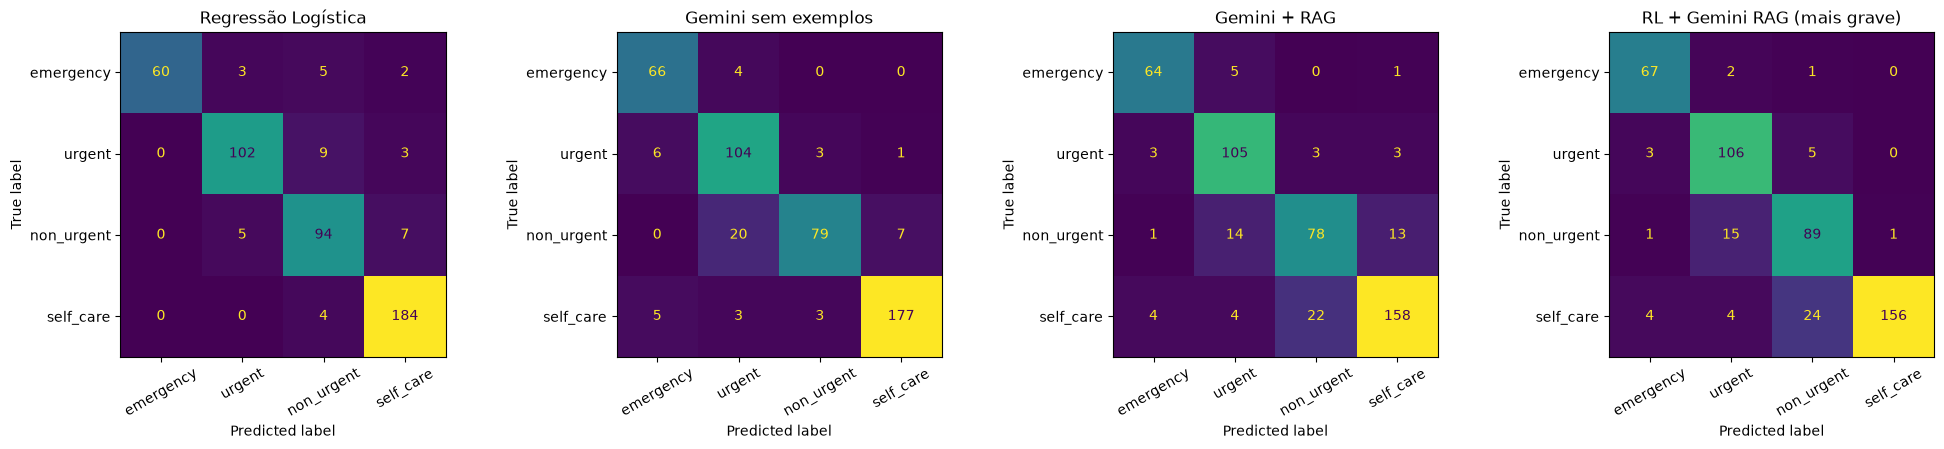

In [8]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 4.5))
for (nome, p), eixo in zip(prev.items(), eixos):
    ConfusionMatrixDisplay.from_predictions(y_teste, p, labels=CLASSES, ax=eixo, colorbar=False, xticks_rotation=30)
    eixo.set_title(nome)
plt.tight_layout()
plt.savefig("matrizes_unidade4.png", dpi=110)
plt.show()

nível do primeiro trecho recuperado comparado com o nível real e com o do Gemini + RAG

In [9]:
top1 = np.array([buscar(t, 1)["urgency"].iloc[0] for t in textos_teste])
rag, real = prev["Gemini + RAG"], y_teste.values
print(f"1º trecho com o mesmo nível do texto        : {(top1 == real).mean():.0%}")
print(f"Gemini + RAG igual ao nível do 1º trecho     : {(rag == top1).mean():.0%}")
print(f"acerto do Gemini + RAG com o 1º trecho certo : {(rag == real)[top1 == real].mean():.0%}")
print(f"acerto do Gemini + RAG com o 1º trecho errado: {(rag == real)[top1 != real].mean():.0%}")
print(f"acerto do Gemini sem exemplos nesses mesmos  : {(prev['Gemini sem exemplos'] == real)[top1 != real].mean():.0%}")

1º trecho com o mesmo nível do texto        : 48%
Gemini + RAG igual ao nível do 1º trecho     : 52%
acerto do Gemini + RAG com o 1º trecho certo : 98%
acerto do Gemini + RAG com o 1º trecho errado: 72%
acerto do Gemini sem exemplos nesses mesmos  : 85%


## 5. Frases novas

as 8 frases da Unidade 3 e 8 em português, traduzidas pelo Gemini antes da Regressão Logística como no site

In [10]:
NOVAS = pd.DataFrame([
    ("you suddenly cannot breathe and your lips are turning blue", "emergency"),
    ("your child has a rash that does not fade when you press a glass against it", "emergency"),
    ("your leg is swollen, red and painful and it is getting worse quickly", "urgent"),
    ("you have had a cough for more than 3 weeks", "non_urgent"),
    ("drink plenty of fluids and get lots of rest", "self_care"),
    ("my head hurts a bit since yesterday, nothing serious", "self_care"),
    ("I think I'm having a heart attack", "emergency"),
    ("I've been feeling low for a few weeks and it's not getting better", "non_urgent"),
    ("estou com uma dor forte no peito que vai para o braço esquerdo", "emergency"),
    ("meu filho está com febre alta e manchas que não somem quando aperto um copo nelas", "emergency"),
    ("estou vomitando sangue", "emergency"),
    ("minha perna está inchada, vermelha e doendo cada vez mais", "urgent"),
    ("tenho tosse há mais de três semanas", "non_urgent"),
    ("tenho me sentido triste há algumas semanas e não melhora", "non_urgent"),
    ("estou com dor de garganta há dois dias, mas consigo comer e beber", "self_care"),
    ("torci o tornozelo, está um pouco inchado mas consigo andar", "self_care"),
], columns=["texto", "esperado"])

ESQUEMA_TRADUCAO = {"type": "OBJECT", "required": ["en"], "properties": {"en": {"type": "STRING"}}}
NOVAS["em inglês"] = [gemini("Translate this message about a health symptom to plain English. "
                             "If it is already in English, return it unchanged.\n\n" + t, ESQUEMA_TRADUCAO)["en"]
                      for t in NOVAS["texto"]]
NOVAS["RL sem tradução"] = classificar(NOVAS["texto"])
NOVAS["RL"] = classificar(NOVAS["em inglês"])
NOVAS["Gemini + RAG"] = gemini_niveis(NOVAS["em inglês"].tolist(), rag=True)
NOVAS["mais grave"] = mais_grave(NOVAS["RL"], NOVAS["Gemini + RAG"])
display(NOVAS.drop(columns="texto"))

COLUNAS = ["RL sem tradução", "RL", "Gemini + RAG", "mais grave"]
pd.DataFrame({"inglês (8)": NOVAS[:8][COLUNAS].eq(NOVAS[:8]["esperado"], axis=0).sum(),
              "português (8)": NOVAS[8:][COLUNAS].eq(NOVAS[8:]["esperado"], axis=0).sum()})

,esperado,em inglês,RL sem tradução,RL,Gemini + RAG,mais grave
0,emergency,you suddenly cannot breathe and your lips are turning blue,emergency,emergency,emergency,emergency
1,emergency,your child has a rash that does not fade when you press a glass against it,self_care,self_care,emergency,emergency
2,urgent,"your leg is swollen, red and painful and it is getting worse quickly",non_urgent,non_urgent,urgent,urgent
3,non_urgent,you have had a cough for more than 3 weeks,non_urgent,non_urgent,non_urgent,non_urgent
4,self_care,drink plenty of fluids and get lots of rest,self_care,self_care,self_care,self_care
5,self_care,"my head hurts a bit since yesterday, nothing serious",self_care,self_care,non_urgent,non_urgent
6,emergency,I think I'm having a heart attack,emergency,emergency,emergency,emergency
7,non_urgent,I've been feeling low for a few weeks and it's not getting better,non_urgent,non_urgent,non_urgent,non_urgent
8,emergency,I have severe chest pain that goes to my left arm,self_care,emergency,emergency,emergency
9,emergency,my son has a high fever and spots that do not fade when I press a glass against them,emergency,self_care,emergency,emergency


,inglês (8),português (8)
RL sem tradução,6,2
RL,6,6
Gemini + RAG,7,8
mais grave,7,8
